In [1]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [5]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

In [8]:
df = pd.read_csv("adult.csv")

In [9]:
df.replace(" ?", np.nan, inplace=True)
df.replace("?", np.nan, inplace=True)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [10]:
print("\nMissing Values")
print(df.isnull().sum())


Missing Values
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64


In [11]:
duplicates = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicates}")

df = df.drop_duplicates()


Duplicate Rows: 24


In [12]:
target = 'income'

X = df.drop(target, axis=1)
y = df[target]

# Convert target into binary

y = y.astype(str).str.strip()
y = y.map({
    '<=50K':0,
    '>50K':1,
    '<=50K.':0,
    '>50K.':1
})

In [13]:
import warnings
warnings.filterwarnings("ignore")

numeric_features = X.select_dtypes(
    include=['int64','float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

In [14]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
test_data = X_test.copy()
test_data[target] = y_test
test_data.to_csv("test_data.csv", index=False)

In [20]:
models = {

    "Logistic Regression":
        LogisticRegression(max_iter=1000),

    "Decision Tree":
        DecisionTreeClassifier(random_state=42),

    "KNN":
        KNeighborsClassifier(n_neighbors=5),

    "Naive Bayes":
        GaussianNB(),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=10,
            max_depth=8,
            random_state=42
        )
}

results = []

In [21]:
for name, model in models.items():

    print(f"\nTraining {name}")

    if name == "Naive Bayes":

        X_train_processed = preprocessor.fit_transform(X_train)
        X_test_processed = preprocessor.transform(X_test)

        X_train_processed = X_train_processed.toarray()
        X_test_processed = X_test_processed.toarray()

        model.fit(X_train_processed, y_train)

        joblib.dump(
        model,
        "saved_models/naive_bayes.py"
    )

        y_pred = model.predict(X_test_processed)

        y_prob = model.predict_proba(
            X_test_processed
        )[:,1]

    else:

        pipeline = Pipeline([
            ('preprocessing', preprocessor),
            ('classifier', model)
        ])

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)

        y_prob = pipeline.predict_proba(
            X_test
        )[:,1]

        filename = name.lower().replace(" ","_") + ".py"

        joblib.dump(
            pipeline,
            f"saved_models/{filename}"
        )

    accuracy = accuracy_score(y_test,y_pred)

    precision = precision_score(y_test,y_pred)

    recall = recall_score(y_test,y_pred)

    f1 = f1_score(y_test,y_pred)

    auc = roc_auc_score(y_test,y_prob)

    mcc = matthews_corrcoef(y_test,y_pred)

    results.append([
        name,
        accuracy,
        auc,
        precision,
        recall,
        f1,
        mcc
    ])


Training Logistic Regression

Training Decision Tree

Training KNN

Training Naive Bayes

Training Random Forest


In [22]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "AUC",
        "Precision",
        "Recall",
        "F1",
        "MCC"
    ]
)

print(results_df)

results_df.to_csv(
    "results/test_data.csv",
    index=False
)

                 Model  Accuracy       AUC  Precision    Recall        F1  \
0  Logistic Regression  0.850184  0.900386   0.734387  0.592474  0.655842   
1        Decision Tree  0.809926  0.740717   0.605213  0.607143  0.606176   
2                  KNN  0.827443  0.851032   0.661818  0.580357  0.618417   
3          Naive Bayes  0.524431  0.721799   0.330522  0.949617  0.490367   
4        Random Forest  0.848801  0.895625   0.780230  0.518495  0.622989   

        MCC  
0  0.566777  
1  0.480912  
2  0.509377  
3  0.314170  
4  0.550601  


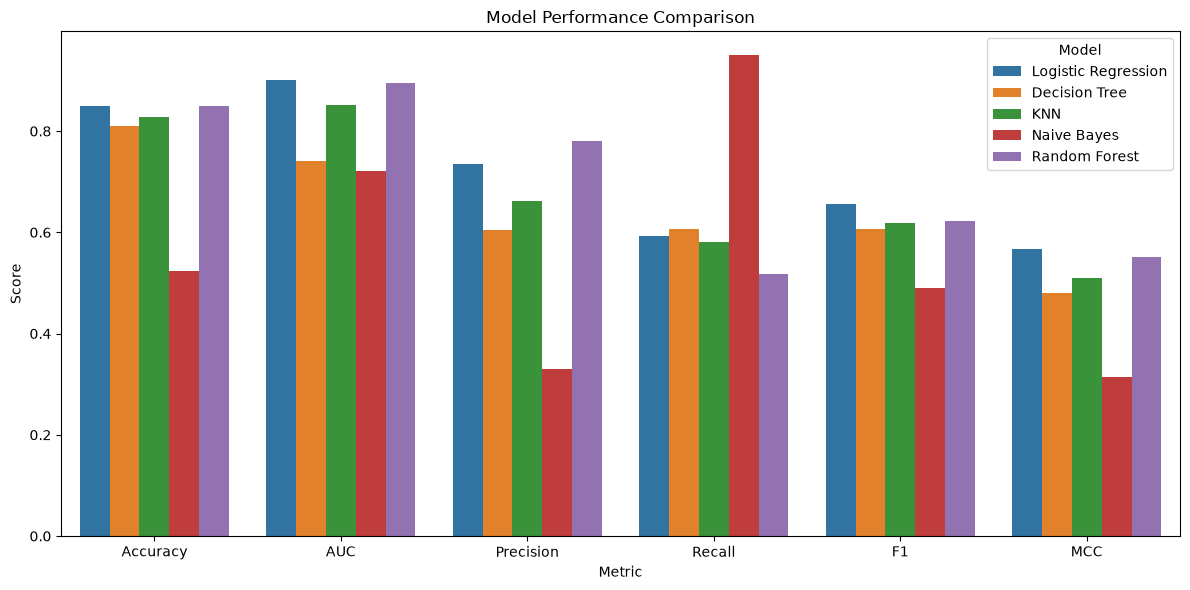

In [23]:
plt.figure(figsize=(12,6))

results_melt = pd.melt(
    results_df,
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melt,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Model Performance Comparison")

plt.tight_layout()

plt.savefig(
    "results/metrics_graph.png"
)

plt.show()